# Multiple Linear Regression

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("YachtHydrodynamics.csv")
df

,"Longitudinal position of the center of buoyancy, adimensional",Prismatic coefficient,Length-displacement ratio,Beam-draught ratio,Length-beam ratio,Froude number,Residuary resistance per unit weight of displacement
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18
...,...,...,...,...,...,...,...
303,-2.3,0.600,4.34,4.23,2.73,0.350,8.47
304,-2.3,0.600,4.34,4.23,2.73,0.375,12.27
305,-2.3,0.600,4.34,4.23,2.73,0.400,19.59
306,-2.3,0.600,4.34,4.23,2.73,0.425,30.48


In [3]:
# separating the features and target columns
y = df.iloc[:, 0].values
X = df.iloc[:, 1:].values

# Add intercept term (bias)
X = np.c_[np.ones(X.shape[0]), X]

In [4]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (308, 7)
Shape of y: (308,)


In [5]:
# 4. Train-Test Split (80%-20%)
np.random.seed(42)  # for reproducibility
rows = X.shape[0]  # number of rows

rp = np.random.permutation(rows)

train_size = int(np.round(rows * 0.8))
train_idx, test_idx = rp[:train_size], rp[train_size:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 246
Testing samples: 62


In [6]:
# Computing Regression Coefficients
# beta = (X^T X)^-1 X^T (y)
XtX = np.dot(X_train.T, X_train)
XtX_inv = np.linalg.inv(XtX)
XtX_inv_Xt = np.dot(XtX_inv, X_train.T)
bt = np.dot(XtX_inv_Xt, y_train)

print("Regression Coefficients (beta):\n", bt)

Regression Coefficients (beta):
 [ 2.77258477e-01 -3.68114951e+00 -1.20140370e+00  4.57901626e-01
  1.10171224e+00 -7.20828137e-01  2.76487696e-03]


In [7]:
# Predict on Test Data
y_pred = np.dot(X_test, bt)

# Display few predictions
preds = pd.DataFrame({'Actual_Target_Values': y_test[:10], 'Predicted_Target_Values': y_pred[:10]})
print(preds.head())
# Evaluate Model Performance
rss = np.sum((y_test - y_pred) ** 2)
mse = rss / len(y_test)
rmse = np.sqrt(rss / len(y_test))

print(f"Residual Sum Square (RSS): {rss:.4f}")
print(f"Mean Square Error (MSE): {mse:.4f}")
print(f"Root Mean Square Error (RMSE): {rmse:.4f}")

   Actual_Target_Values  Predicted_Target_Values
0                  -5.0                -2.370945
1                  -2.3                -2.368008
2                  -2.3                -2.247765
3                  -2.3                -2.403073
4                  -2.3                -2.442642
Residual Sum Square (RSS): 131.8594
Mean Square Error (MSE): 2.1268
Root Mean Square Error (RMSE): 1.4583


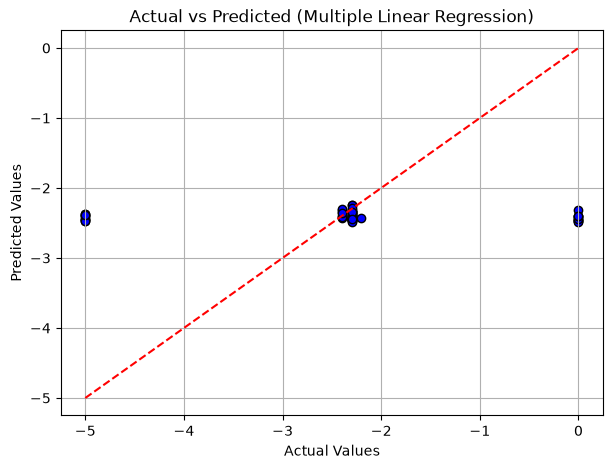

                                             Feature  Coefficient
0                                          Intercept     0.277258
1                              Prismatic coefficient    -3.681150
2                          Length-displacement ratio    -1.201404
3                                 Beam-draught ratio     0.457902
4                                  Length-beam ratio     1.101712
5                                      Froude number    -0.720828
6  Residuary resistance per unit weight of displa...     0.002765


In [8]:
# Visualization of Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='blue', edgecolors='black')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted (Multiple Linear Regression)")
plt.grid(True)
plt.show()

coef_table = pd.DataFrame({
    'Feature': ['Intercept'] + list(df.columns[1:]),
    'Coefficient': bt
})

print(coef_table)